# Bacterial motion: full native recordings to relaxation spectra


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测 → 物理目标：bsubtilis_differential_dynamics

**观测 y：** frames(1, 2, 2000, 128, 128)。具体单位以本Notebook数据表及README为准。

**恢复目标 x：** 39波数环的A/B/Gamma/beta与有效速度。

**GT/参考来源：** **没有独立GT：以下仅为原方法参考重建，不能解释为物理真值。**

**由观测恢复目标：** D(q,t)=A[1-exp(-(Gamma*t)^beta)]+B。本地路径为 `solvers.analyze_movie→fit_multifrequency→fit_speed`。现有Notebook包含主动调用路径；本次只读审核未重跑，保留的execution_count/图像只说明已有输出，不能声称本轮执行。

**现有实验与图：** 保留图像输出位于cell 11, 13, 15, 17（cell编号按文件内从0计）。章节包括：# Bacterial motion: full native recordings to relaxation spectra；## 2. Data；## 3. Physics；## 4. Method；## 5. Results；### Forward physics and explicit inversion；### Controlled scientific comparisons；### Native fields, structure functions and fresh fits；### All inferred parameter spectra and independently reproduced upstream parity。应联合阅读观测图、完整恢复目标、参考差异与残差/敏感性实验；方法一致性不等于物理精度。

**限制：** 统计动力学参数逆；非逐细胞轨迹或空间图像恢复。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

Infer length-dependent relaxation spectra and effective ballistic speed scales from two complete noisy fluorescence movies of motile bacteria.

The target consists of effective contrast A, signed background B, relaxation Gamma, compression beta at 39 specified q rings, and a characteristic ballistic scale. There is no independently known microscopic truth or exact depth calibration. One pixel is75.59/128 µm, fs=100Hz. Full fields and all frames are retained.


# Benchmark v2: directly observed DDM model class

The historical source fit computes quasi-log interpolated structure functions and warmstarted parameter fields. Those computations and parity evidence remain unchanged, but no longer define a uniquely required finite trajectory. Current acceptance independently forms image-difference structure functions at9declared physical delays, retaining all39rings and both full movies. It retains the original perrecording relativeL2<=0.02 quality limit and positiveA/Gamma, beta>=1, signedB. Recording1(index1) has fixedbeta1.35 (absolute1e-10). Speed is the analytic unweighted log-rate/geometricmean estimate exp(mean(log(Gamma/q))), relative tolerance1e-6. No hidden parameter map is loaded. This defines a measurement-compatible conditional model class, not biological ground truth or an equivalence claim for all noisy fitted parameters.

Independent generic bounded nonlinear least squares fits the9directly measured lag values at each ring from observation-derived starts, without invoking source fitting/preprocessing routines. It obtains recording errors0.008933544204722194 and0.00528919484352074, passing. Multiplying all rates and speed by3 preserves speed identity but gives observation errors0.26681182606908754 and0.14011204832129814, failing. These are valid physical outputs rejected by observation quality rather than malformed-input checks. Old image/parameter criteria are archived privately in benchmark_readiness_20261029/bsubtilis_metrics_v1.json; control evidence is bsubtilis_v2_controls.json/log. Original arrays/source reconstruction are unchanged. Notebook old parameter comparisons are historical reproduction diagnostics, not current acceptance requirements.



## 2. Data

The file `data/raw_data.npz` contains both full native movies; no frames or spatial pixels were removed, averaged or resized.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| frames | (1, 2, 2000, 128, 128) | uint8 | Native fluorescence intensities in ADU; axes batch, recording, time, downward y, rightward x. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Organism | B. subtilis | dimensionless identifier | Author-described motile bacterial sample. |
| Temperature | 33 | degrees Celsius | Author-reported acquisition temperature. |
| Frame rate fs | 100 | Hz | All 2000 frames retained for each condition. |
| Pixel spacing | 75.59/128 = 0.590546875 | micrometers/pixel | Exact calibration used in the supplied analysis; its text rounds this to 0.591. |
| Native dimensions | 128 by 128 | pixels | Finite camera field, 75.59 micrometers on each side. |
| Intensity encoding | unsigned 8 bit | ADU | Native detector values; no photon conversion or measured noise variance supplied. |
| Optical context | point-scanning confocal, 63x oil objective | dimensionless identifier | Author-reported instrument context. |
| Focal conditions | native identifiers 01umE and 16umE | dimensionless identifiers | Two distinct focal conditions; no independently verified metric depth is imposed. |
| Spatial Fourier boundary | periodic discrete basis, no window or padding | pixels | FFT applied to the entire finite field; normalization 1/sqrt(128*128). |
| Wavevector coordinates | kx=2pi*fftfreq(128)[:65]/pixel_spacing; ky=2pi*fftshift(fftfreq(128))/pixel_spacing | rad/micrometer | Real-FFT half-plane, x unshifted and y shifted. |
| Radial edges | 90 equally spaced values from 0 to 90*2pi/75.59 | rad/micrometer | Bin index is left search insertion index of the mode radius in these edges. |
| Ring weights | 2 except x DC/Nyquist columns 1 | dimensionless | Full-plane multiplicity of each stored Fourier mode. |
| Excluded Fourier modes | first x column, central y row, insertion index >=90 | dimensionless indices | Fixed cross mask; no target-dependent mask. |
| Ring center and output selection | weighted mean mode radius; retain centers 0.75 through 4 | rad/micrometer | Ascending selected centers define the 39 output positions. |
| Delay averaging | all T-l overlapping pairs | frame pairs | No temporal wrapping or padded pairs contribute. |

The actual movies are from the authors' PLU-BACTERIA archive, released under CC BY 4.0. Attribution and source are listed below. The archive's `noswarm_depths_at_same_time/*E` names differ from the tutorial's `swarm_depth_sequence/*F` example names; this task analyzes the actual supplied E movies and does not claim to reproduce a particular published F-movie figure.


This active review reconstructs both complete author movies (2000×128×128 each), identifies the original upstream estimates separately, and evaluates freshly computed local results. The native E filenames differ from the source tutorial's F examples; these are rebound real observations, not a reproduction of a cached paper figure. Data: Lattuada, Krautgasser, Lavaud, Giavazzi and Cerbino, Phaidra PLU-BACTERIA (CC BY 4.0). Code-derived mathematics: fastddm GPL3+.


## 3. Physics

The two complete author recordings show motile B. subtilis in distinct focal conditions, identified by the native filenames `BacCFP_33deg_01umE` and `BacCFP_33deg_16umE`. Preserve this order. Their precise physical depth separation is not independently verified. Let I(t,x,y) denote image intensity in ADU and let F(t,k) be its spatial Fourier transform divided by sqrt(HW), where H and W are the image height and width. For a positive integer delay l, define the image structure function as the mean of |F(t+l,k)-F(t,k)|² over all T-l available frame pairs, then average over the specified radial Fourier ring. T is the number of frames. The effective acquisition model is


$$
D(q,\tau)=A(q)\left[1-\exp\left(-(\Gamma(q)\tau)^{\beta(q)}\right)\right]+B(q),
\qquad \tau=l/f_s.
$$


Here q is radial angular spatial frequency in rad/micrometer, tau is delay in seconds, fs is frame rate, A>0 is dynamic contrast in ADU², B is an effective additive background in ADU², Gamma>0 is relaxation rate in s^-1, and beta>=1 is a dimensionless compression exponent. B is a fitted effective offset and can be signed; it is not asserted to be a nonnegative instrument variance. The ensemble ballistic scale v>0 in micrometers/s relates Gamma to vq through an unweighted fit of log(Gamma) to log(vq). Finite recordings, weak contrast, imperfect radial isotropy and coupled parameters make the inverse problem difficult.


## 4. Method

Differential dynamic microscopy can form the finite-overlap structure function efficiently using zero-padded temporal Fourier correlation. Retain the exact spatial normalization, radial weights, excluded cross and overlapping-pair denominator. Weighted spatial dispersion can guide nonlinear curve fitting without being interpreted as a calibrated temporal uncertainty.

Fit a compressed exponential relaxation at each selected spatial frequency. The offset and amplitude can be initialized from temporal Fourier variance and high-frequency noise. Neighboring frequency fits can provide stable initial values. The two focal conditions need not have identical compression behavior: a variable exponent for the first recording and fixed beta=1.35 for the second define the selected standard estimator. A logarithmic rate-versus-frequency comparison provides an effective ballistic scale and reveals deviations from a single-scale model.


## 5. Results

The preserved code below contains the active reconstruction and comparison path. Its saved outputs are retained from the earlier execution. This documentation edit does not rerun that path; displayed measurements remain evidence of the stored execution rather than a new numerical run.


In [1]:
from pathlib import Path
import sys,time,json,numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations
from src.solvers import analyze_movie,fit_curve
from src.physics_model import structure_model
from src.visualization import figures
from evaluation.judge import evaluate
frames=load_observations(ROOT/'data/raw_data.npz')
assert frames.shape==(1,2,2000,128,128)
print('Active full native input:',frames.shape,frames.dtype)


Active full native input: (1, 2, 2000, 128, 128) uint8


### Forward physics and explicit inversion
For each integer lag l, D is the finite-overlap mean of squared differences of spatial Fourier amplitudes, normalized by sqrt(HW), then weighted over the fixed radial ring. No temporal wrap or detector crop is used. The direct model is

$D(q,\tau)=A(q)[1-\exp(-(\Gamma(q)\tau)^{\beta(q)})]+B(q)$.

Here q is rad/µm, tau=l/fs seconds, A/B ADU², Gamma s⁻¹, beta dimensionless. Finite-overlap autocorrelation is evaluated with length2T zero-padded temporal FFTs. Radial multiplicities and the removed Fourier cross preserve the original source convention. Spatial dispersion weights the compressed-exponential least squares. The first record fits beta; the second fixes1.35. Warm starts traverse frequency bins in the original order. Local bound transforms and residuals feed general MINPACK LM; no domain library is imported. Finally minimize sum[log(Gamma)-log(vq)]² for v>0. This effective scale is not an independently tracked mean velocity.


In [2]:
start=time.perf_counter()
results=[analyze_movie(movie,c) for c,movie in enumerate(frames[0])]
parameters=np.stack([a['parameters'][a['selected']] for a in results])[None]
speed=np.array([a['speed'] for a in results])[None]
runtime=time.perf_counter()-start
(ROOT/'output').mkdir(exist_ok=True)
np.savez_compressed(ROOT/'output/reconstruction.npz',reconstruction=parameters,speed=speed)
with np.load(ROOT/'evaluation/baseline_reference.npz',allow_pickle=False) as z:
    upstream=z['reconstruction'][0].copy();upstream_speed=z['speed'].copy()
measurements={'fresh_runtime_seconds':runtime,'fresh_speed_um_s':speed.tolist(),'upstream_speed_um_s':upstream_speed.tolist(),'parameter_max_absolute_difference':float(np.max(abs(parameters[0]-upstream)))}
print(json.dumps(measurements,indent=2))
assert evaluate(ROOT/'output/reconstruction.npz',ROOT/'output/judge_report.json')==0
report=json.loads((ROOT/'output/judge_report.json').read_text())
print(json.dumps(report,indent=2))


{
  "fresh_runtime_seconds": 4.738405500072986,
  "fresh_speed_um_s": [
    [
      9.25986768437256,
      27.98801674661428
    ]
  ],
  "upstream_speed_um_s": [
    [
      9.25986768437256,
      27.98801674661428
    ]
  ],
  "parameter_max_absolute_difference": 0.0
}
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "condition0_amplitude_relative_l2": 0.0,
    "condition0_background_relative_l2": 0.0,
    "condition0_relaxation_relative_l2": 0.0,
    "condition0_exponent_relative_l2": 0.0,
    "condition0_speed_relative_error": 0.0,
    "condition0_observation_relative_l2": 0.009520924174246286,
    "condition1_amplitude_relative_l2": 0.0,
    "condition1_background_relative_l2": 0.0,
    "condition1_relaxation_relative_l2": 0.0,
    "condition1_exponent_relative_l2": 0.0,
    "condition1_speed_relative_error": 0.0,
    "condition1_observation_relative_l2": 0.0058330466058011295
  },
  "thresholds": {
    "condition0_amplitude_relative_l2": {
      "comparison": "<=",
  

### Controlled scientific comparisons

The selected standard method remains unchanged. The following diagnostics refit all39 frequency curves derived from each complete movie: simple exponential beta1, common fixed beta1.35, and unweighted least squares with the canonical variable/fixed exponent choice. Initial parameters come from the fresh canonical fits, so these diagnostics isolate model/weight sensitivity rather than creating an uncomputed baseline. All curves and speed summaries below are computed now. Spatial SD is not a calibrated independent temporal uncertainty.


In [3]:
diagnostics=[]
for c,a in enumerate(results):
    selected=a['selected'];p=a['parameters'][selected];d=a['data'][selected];err=a['error'][selected];t=a['tau']
    groups=[p.copy()]
    for beta in (1.,1.35):
        rows=[]
        for row,y,e in zip(p,d,err):
            initial=row.copy();initial[3]=beta
            rows.append(fit_curve(t,y,initial,weights=1/e,vary_beta=False)[0])
        groups.append(np.array(rows))
    groups.append(np.array([fit_curve(t,y,row,weights=None,vary_beta=c==0)[0] for row,y in zip(p,d)]))
    diagnostics.append(groups)
review_figures,plot_sources=figures(frames,results,upstream,diagnostics)
measurements['diagnostic_fit_relative_l2']=[plot_sources[f'condition{c}_diagnostic_fit_relative_l2'].tolist() for c in range(2)]
measurements['diagnostic_speed_um_s']=[plot_sources[f'condition{c}_diagnostic_speed'].tolist() for c in range(2)]
measurements['judge_metrics']=report['metrics']
print(json.dumps(measurements,indent=2))

plt.close("all") # Suppress automatic duplicate inline figure emission.


{
  "fresh_runtime_seconds": 4.738405500072986,
  "fresh_speed_um_s": [
    [
      9.25986768437256,
      27.98801674661428
    ]
  ],
  "upstream_speed_um_s": [
    [
      9.25986768437256,
      27.98801674661428
    ]
  ],
  "parameter_max_absolute_difference": 0.0,
  "diagnostic_fit_relative_l2": [
    [
      0.008686161150717462,
      0.027776420413354798,
      0.012729205262581455,
      0.008424903067341723
    ],
    [
      0.0038065583320889113,
      0.00563977917872764,
      0.0038065590434721523,
      0.003660118097391026
    ]
  ],
  "diagnostic_speed_um_s": [
    [
      9.259867684365075,
      9.759737881813829,
      8.986041353496393,
      9.715822564112148
    ],
    [
      27.98801674661308,
      38.89615421396492,
      27.988016682178095,
      28.30420755268503
    ]
  ],
  "judge_metrics": {
    "condition0_amplitude_relative_l2": 0.0,
    "condition0_background_relative_l2": 0.0,
    "condition0_relaxation_relative_l2": 0.0,
    "condition0_exponent

### Native fields, structure functions and fresh fits


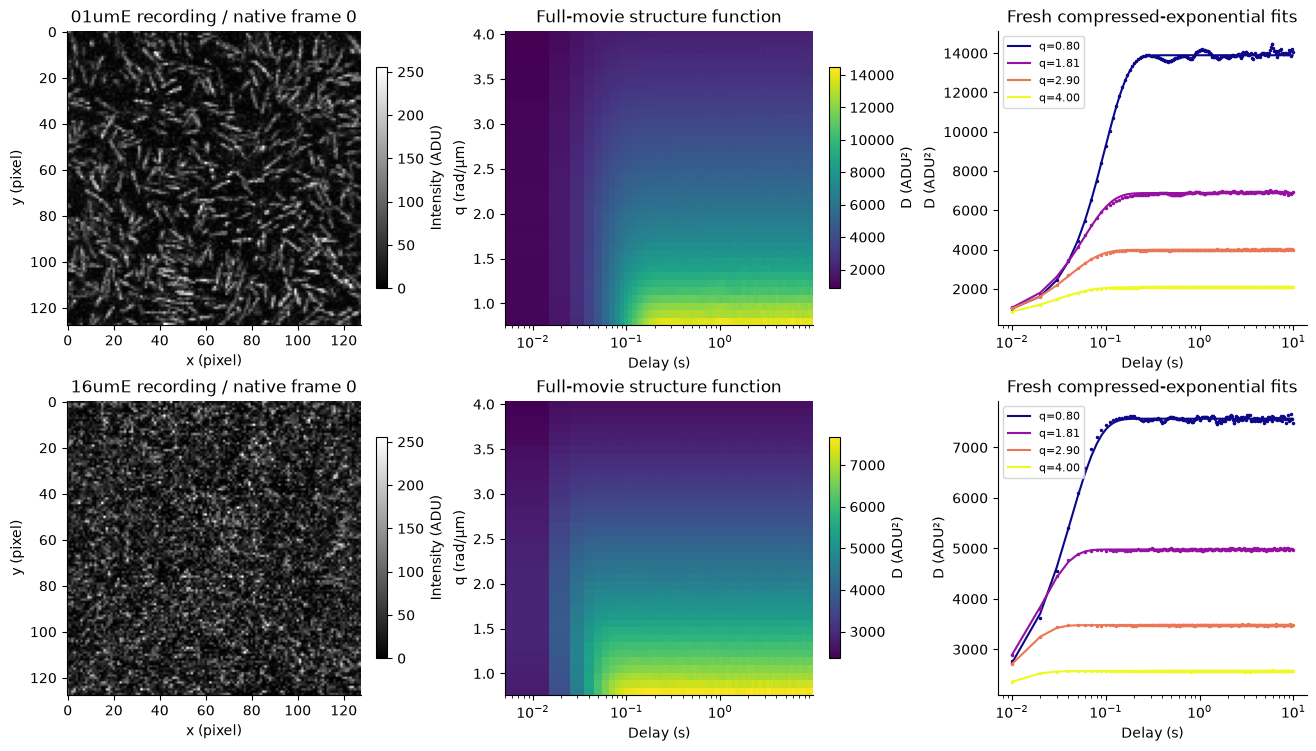

In [4]:
display(review_figures[0][1])
plt.close(review_figures[0][1])

### All inferred parameter spectra and independently reproduced upstream parity


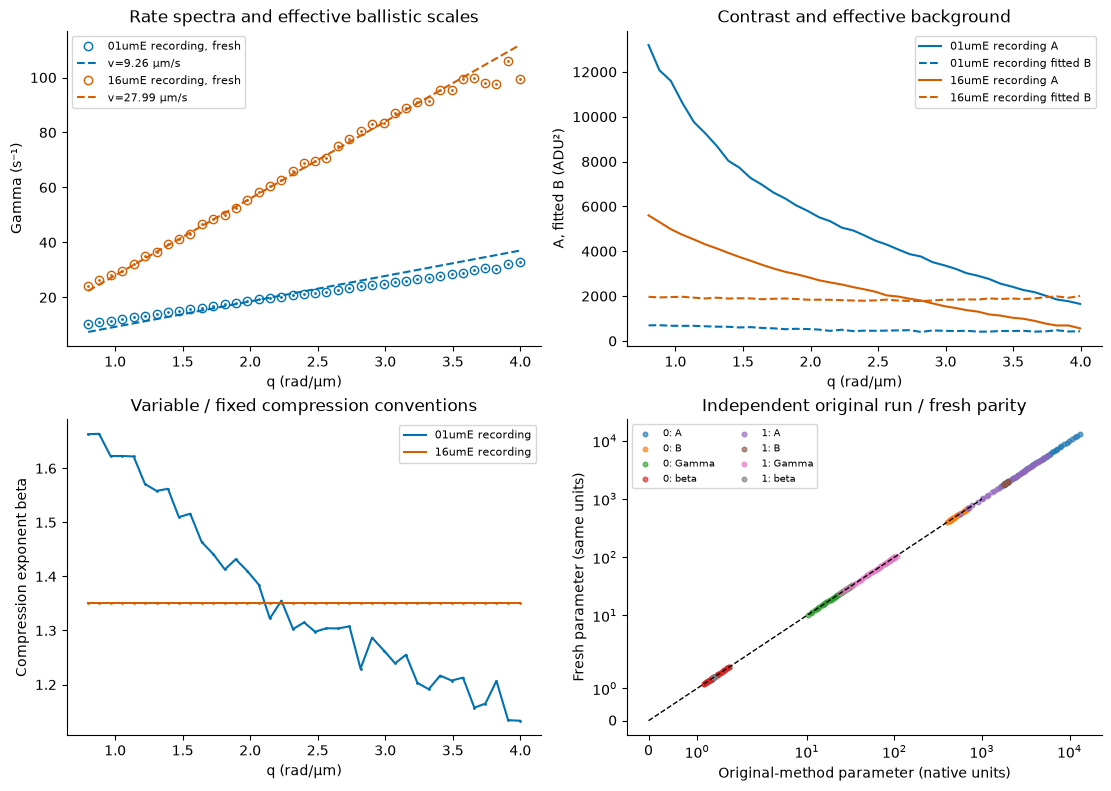

In [5]:
display(review_figures[1][1])
plt.close(review_figures[1][1])

### Scaled correlations and the source isotropic model distribution

The dimensionless distribution is the computed 3-D isotropic model sine transform P(n)=2n/pi integral exp(-t^1.35)t sin(nt)dt, with n=v/v0. It is an interpretation of a shared compressed-exponential model, not additional measured trajectories. Both original correlation groups and the original velocity-distribution comparison are retained.


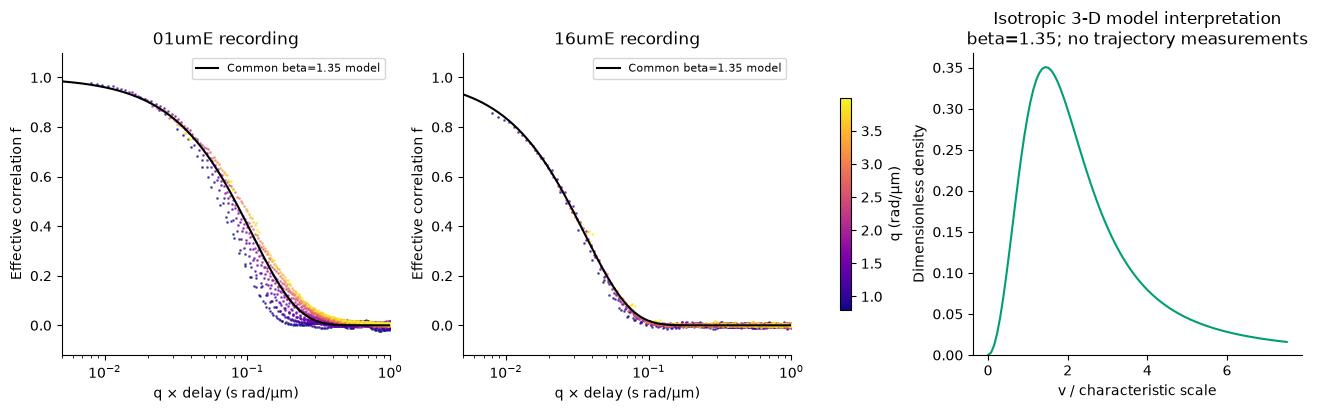

In [6]:
display(review_figures[2][1])
plt.close(review_figures[2][1])

### Controlled compression and weighting comparisons


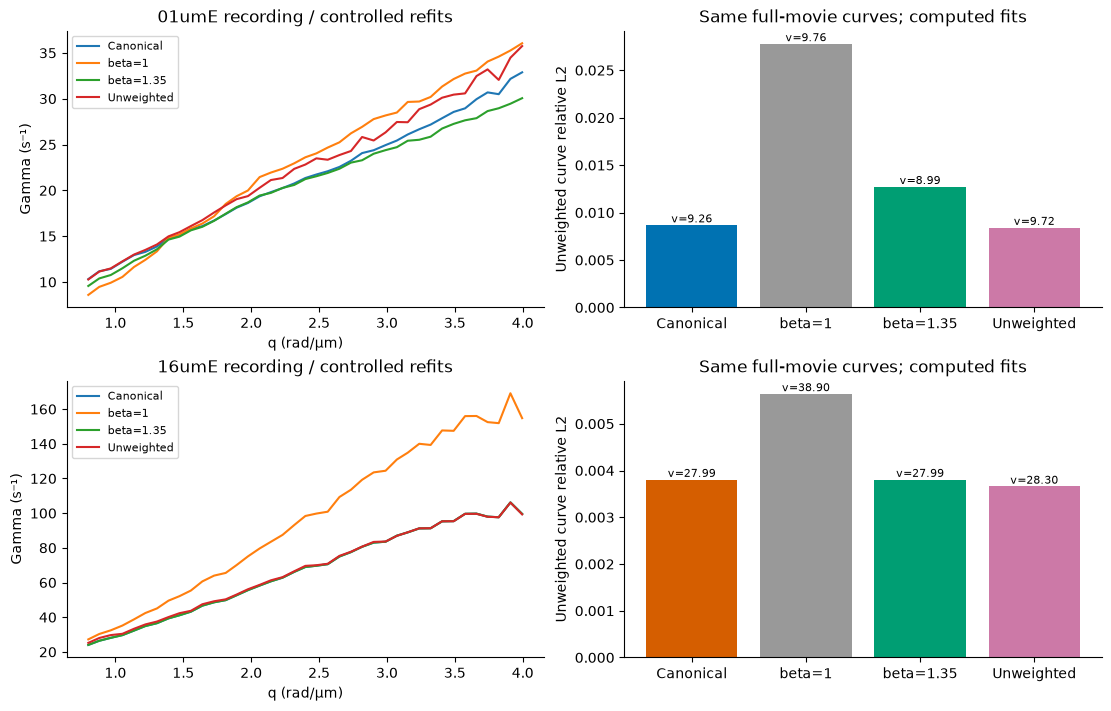

In [7]:
display(review_figures[3][1])
plt.close(review_figures[3][1])

## 6. Conclusion

### Result and limitations

The original and fresh estimates agree at current numerical precision. The second recording has a larger effective ballistic scale; this describes these actual E movies under the selected empirical model. Independent direct time-difference consistency is checked at nine physical delays using public full movies. Excellent method agreement does not establish biological truth, exact velocity distributions, or the unverified focal depth. The controlled curves expose the consequence of compression/weight assumptions. References: The Hitchhiker's Guide to Differential Dynamic Microscopy, arXiv2507.05058v2, DOI10.1063/5.0289471; actual data https://phaidra.univie.ac.at/detail/o:2170175 .

The inferred speed is the compressed-exponential ballistic scale of the measured structure functions, not a set of tracked cell velocities. Changing beta and weighting tests the empirical relaxation model; spatial dispersion does not supply independent temporal noise calibration.
